<a href="https://colab.research.google.com/github/mariarango521-oss/proyecto_analitica_financiera/blob/main/03_analisis_exploratorio_portafolio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · Análisis exploratorio de datos financieros

**Financial Analytics Lab · Python · pandas · NumPy · matplotlib**

**Pregunta orientadora:** ¿qué revelan los rendimientos históricos sobre el comportamiento y la variabilidad de los activos de un portafolio?

En los módulos anteriores aprendimos a representar inversiones y preparar precios históricos. Ahora analizaremos los rendimientos mediante medidas descriptivas y visualizaciones. El objetivo es **explicar qué representa cada indicador, verificar su cálculo e interpretar sus limitaciones**.

**Aprendizajes:** rendimiento simple; media y mediana; varianza y desviación estándar; cuantiles; distribuciones; precios normalizados; gráficos; interpretación financiera.

**Trabajo autónomo:** ejecuta las celdas en orden, completa cada «Tu práctica» y redacta conclusiones propias. Los datos provienen de un servicio externo y sus resultados pueden variar.

## 0 · Planteamiento del problema

Un analista necesita comparar tres activos: MSFT, AAPL y JPM. ¿Cuál presentó mayor rendimiento promedio por observación? ¿Cuál mostró mayor dispersión? ¿Qué revelan sus distribuciones?

Un precio nominal más alto no implica mayor rentabilidad. Para comparar activos utilizaremos variaciones relativas y medidas estadísticas.

**Alcance:** el análisis describe un período histórico; no permite anticipar rendimientos ni recomendar inversiones.

## 1 · Preparar los datos

En el módulo 02 generamos `precios_portafolio.csv`. Puedes utilizar ese archivo si lo conservaste. Para que el cuaderno también funcione por separado, la opción predeterminada consulta precios históricos mediante `yfinance`.

**ETL:** extracción de precios, validación de fechas y valores, y preparación de una tabla común. `auto_adjust=True` solicita precios ajustados según la fuente. El límite `end` es exclusivo.

In [ ]:
%pip -q install yfinance pandas numpy matplotlib

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from datetime import datetime, timezone

TICKERS = ["MSFT", "AAPL", "JPM"]
INICIO = "2024-01-01"
FIN = "2025-01-01"
USAR_CSV_MODULO_02 = False
print("Fecha de consulta UTC:", datetime.now(timezone.utc).isoformat(timespec="seconds"))

Fecha de consulta UTC: 2026-11-12T01:46:10+00:00


In [ ]:
if USAR_CSV_MODULO_02:
    from google.colab import files
    archivos = files.upload()
    if "precios_portafolio.csv" not in archivos:
        raise FileNotFoundError("Sube precios_portafolio.csv del módulo 02.")
    precios = pd.read_csv("precios_portafolio.csv", index_col="Fecha", parse_dates=["Fecha"])
else:
    series = []
    for ticker in TICKERS:
        tabla = yf.download(ticker, start=INICIO, end=FIN,
                            auto_adjust=True, progress=False, multi_level_index=False)
        if tabla.empty or "Close" not in tabla.columns:
            raise RuntimeError(f"No se pudo consultar {ticker}. Verifica la conexión y la fuente.")
        series.append(tabla[["Close"]].rename(columns={"Close": ticker}))
    precios = pd.concat(series, axis=1, join="inner")

precios.index = pd.to_datetime(precios.index)
precios = precios.sort_index()
precios = precios.loc[~precios.index.duplicated(keep="first")]
precios = precios.apply(pd.to_numeric, errors="coerce").dropna(how="any")
precios = precios.loc[(precios > 0).all(axis=1)]
if len(precios) < 3:
    raise RuntimeError("No hay suficientes observaciones válidas.")
print("Dimensiones:", precios.shape)
display(precios.head())
print("Valores faltantes:", precios.isna().sum().to_dict())

Dimensiones: (252, 3)


,MSFT,AAPL,JPM
Date,,,
2024-01-02,363.117920,183.403992,161.472733
2024-01-03,362.853546,182.030777,160.768951
2024-01-04,360.249176,179.718948,161.835831
2024-01-05,360.063141,178.997696,162.647827
2024-01-08,366.858093,183.324966,162.411758


Valores faltantes: {'MSFT': 0, 'AAPL': 0, 'JPM': 0}


**Tu práctica 1:** identifica la primera y última fecha, número de observaciones y cantidad de activos. Explica por qué es necesario comparar fechas comunes y por qué no se deben inventar precios para completar observaciones faltantes.

In [ ]:
print("Primera fecha:", precios.index.min().date())
print("Última fecha:", precios.index.max().date())
print("Número de observaciones:", len(precios))
print("Cantidad de activos:", precios.shape[1])
print("Activos:", list(precios.columns))

Primera fecha: 2024-01-02
Última fecha: 2024-12-31
Número de observaciones: 252
Cantidad de activos: 3
Activos: ['MSFT', 'AAPL', 'JPM']


Es importante comparar fechas comunes para garantizar resultados consistentes. No se deben inventar precios faltantes porque se alterarían los rendimientos y se generarían conclusiones incorrectas.

## 2 · Rendimientos simples

El rendimiento entre dos observaciones consecutivas se define como:

\[r_t = \frac{P_t}{P_{t-1}}-1\]

Un resultado de 0,02 representa un rendimiento del 2 %. El primer rendimiento no está definido porque falta un precio anterior. `pct_change(fill_method=None)` calcula las variaciones relativas de cada columna.

In [ ]:
rendimientos = precios.pct_change(fill_method=None).dropna(how="any")
rendimientos_pct = rendimientos * 100
display(rendimientos_pct.head())

activo = precios.columns[0]
manual = precios[activo].iloc[1] / precios[activo].iloc[0] - 1
calculado = rendimientos[activo].iloc[0]
assert np.isclose(manual, calculado)
print(f"Comprobación {activo}: {manual:.6f} = {calculado:.6f}")

,MSFT,AAPL,JPM
Date,,,
2024-01-03,-0.072807,-0.748738,-0.435851
2024-01-04,-0.717747,-1.270021,0.663610
2024-01-05,-0.051641,-0.401322,0.501741
2024-01-08,1.887156,2.417501,-0.145141
2024-01-09,0.293573,-0.226329,-0.790600


Comprobación MSFT: -0.000728 = -0.000728


**Tu práctica 2:** comprueba manualmente el rendimiento de otro activo y explica el signo del resultado. Distingue entre precio (USD por acción) y rendimiento (proporción o porcentaje).

In [ ]:
activo = "AAPL"

manual = precios[activo].iloc[1] / precios[activo].iloc[0] - 1
calculado = rendimientos[activo].iloc[0]

print(f"Rendimiento manual: {manual:.6f}")
print(f"Rendimiento pandas: {calculado:.6f}")

assert np.isclose(manual, calculado)

Rendimiento manual: -0.007487
Rendimiento pandas: -0.007487


El rendimiento negativo indica una disminución en el precio de la acción, lo que representa una variación desfavorable para el inversionista.

## 3 · Media y mediana

La **media aritmética** resume el rendimiento promedio por observación: \(\bar r = \sum r_i/n\). La **mediana** divide los valores ordenados en dos mitades y suele ser menos sensible a valores extremos.

**Importante:** el promedio de rendimientos por observación no equivale al rendimiento acumulado del período ni a una rentabilidad anual.

In [ ]:
centro = pd.DataFrame({
    "Media (%)": rendimientos_pct.mean(),
    "Mediana (%)": rendimientos_pct.median()
})
display(centro.round(4))
muestra = rendimientos_pct.iloc[:5, 0]
media_manual = sum(muestra) / len(muestra)
assert np.isclose(media_manual, muestra.mean())
print("Media de cinco observaciones comprobada:", round(media_manual, 5))

,Media (%),Mediana (%)
MSFT,0.0619,0.1154
AAPL,0.1312,0.1596
JPM,0.1524,0.1710


Media de cinco observaciones comprobada: 0.26771


**Tu práctica 3:** compara la media y la mediana de cada activo. ¿En cuál es mayor su diferencia? Propón una explicación que puedas contrastar después con un histograma.

In [ ]:
centro["Diferencia absoluta"] = (
    centro["Media (%)"] - centro["Mediana (%)"]
).abs()

display(centro.round(4))
print("Activo con mayor diferencia:",
      centro["Diferencia absoluta"].idxmax())

,Media (%),Mediana (%),Diferencia absoluta
MSFT,0.0619,0.1154,0.0535
AAPL,0.1312,0.1596,0.0285
JPM,0.1524,0.1710,0.0186


Activo con mayor diferencia: MSFT


La diferencia entre la media y la mediana permite identificar posibles valores extremos en los rendimientos. El activo con mayor diferencia podría presentar variaciones más pronunciadas o valores atípicos. Esto se puede comprobar posteriormente mediante un histograma para observar la distribución de sus rendimientos.

## 4 · Dispersión y volatilidad histórica

La **varianza muestral** resume las desviaciones cuadráticas respecto a la media: \(s^2=\sum(r_i-\bar r)^2/(n-1)\). La **desviación estándar** es su raíz cuadrada. Utilizaremos `ddof=1` para trabajar con la definición muestral.

En series de rendimientos, la desviación estándar es una medida habitual de volatilidad histórica. Sin embargo, no captura todas las dimensiones del riesgo financiero.

In [ ]:
dispersion = pd.DataFrame({
    "Desv. estándar (%)": rendimientos_pct.std(ddof=1),
    "Mínimo (%)": rendimientos_pct.min(),
    "Máximo (%)": rendimientos_pct.max()
})
display(dispersion.round(4))
muestra = rendimientos_pct.iloc[:5, 0].to_numpy()
media = muestra.mean()
varianza_manual = ((muestra - media) ** 2).sum() / (len(muestra) - 1)
desviacion_manual = np.sqrt(varianza_manual)
assert np.isclose(desviacion_manual, pd.Series(muestra).std(ddof=1))
print("Desviación estándar comprobada:", round(desviacion_manual, 5))

,Desv. estándar (%),Mínimo (%),Máximo (%)
MSFT,1.2567,-6.0528,2.6599
AAPL,1.4123,-4.8167,7.2649
JPM,1.4815,-6.4678,11.5445


Desviación estándar comprobada: 0.97626


**Tu práctica 4:** ordena los activos por desviación estándar. Explica por qué una desviación mayor describe más dispersión en esta muestra, pero no demuestra por sí sola que el activo sea una peor inversión.

In [ ]:
ordenados = dispersion.sort_values(
    by="Desv. estándar (%)",
    ascending=False
)

display(ordenados.round(4))

,Desv. estándar (%),Mínimo (%),Máximo (%)
JPM,1.4815,-6.4678,11.5445
AAPL,1.4123,-4.8167,7.2649
MSFT,1.2567,-6.0528,2.6599


El activo con mayor desviación estándar presenta mayor variación en sus rendimientos. Esto indica más dispersión, pero no significa necesariamente que sea una peor inversión.

## 5 · Cuantiles y valores extremos

Los **cuantiles** dividen la distribución ordenada. Q1 es el percentil 25 y Q3 el percentil 75. El **rango intercuartílico** es Q3 − Q1.

Una regla exploratoria identifica observaciones fuera de Q1 − 1,5 × IQR y Q3 + 1,5 × IQR. Esos valores requieren interpretación, no eliminación automática: movimientos extremos pueden corresponder a acontecimientos reales.

In [ ]:
q1 = rendimientos_pct.quantile(0.25)
q3 = rendimientos_pct.quantile(0.75)
iqr = q3 - q1
fuera = rendimientos_pct.lt(q1 - 1.5 * iqr) | rendimientos_pct.gt(q3 + 1.5 * iqr)
cuantiles = pd.DataFrame({
    "Q1 (%)": q1, "Q3 (%)": q3, "IQR (pp)": iqr,
    "Observaciones fuera de límites": fuera.sum()
})
display(cuantiles.round(4))

,Q1 (%),Q3 (%),IQR (pp),Observaciones fuera de límites
MSFT,-0.6056,0.9165,1.5220,7
AAPL,-0.6713,0.9332,1.6045,6
JPM,-0.5579,0.8482,1.4061,10


**Tu práctica 5:** identifica el activo con más observaciones fuera de los límites exploratorios. Explica por qué no debes eliminarlas sin verificar su origen.

In [ ]:
display(cuantiles.sort_values(
    by="Observaciones fuera de límites",
    ascending=False
))

,Q1 (%),Q3 (%),IQR (pp),Observaciones fuera de límites
JPM,-0.557895,0.848204,1.406099,10
MSFT,-0.605564,0.916470,1.522034,7
AAPL,-0.671311,0.933161,1.604472,6


El activo con más observaciones fuera de los límites presenta más valores extremos en sus rendimientos. No deben eliminarse sin verificar su origen, porque pueden representar movimientos reales del mercado y afectar el análisis financiero.

## 6 · Visualizar los resultados

Un gráfico debe responder una pregunta:

- **Precios normalizados (base 100):** ¿cómo evolucionó cada activo respecto a su nivel inicial?
- **Histograma:** ¿cómo se distribuyeron los rendimientos?
- **Diagrama de caja:** ¿cómo se comparan medianas, cuartiles y observaciones extremas?

Los precios normalizados se calculan como 100 × precio actual / precio inicial. No incluyen dividendos ni otros flujos adicionales.

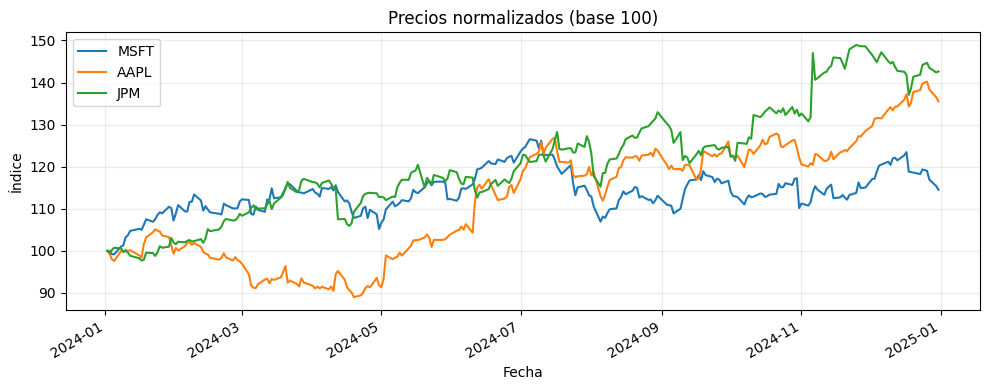

In [ ]:
normalizados = precios.div(precios.iloc[0]).mul(100)
ax = normalizados.plot(figsize=(10, 4))
ax.set(title="Precios normalizados (base 100)", xlabel="Fecha", ylabel="Índice")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

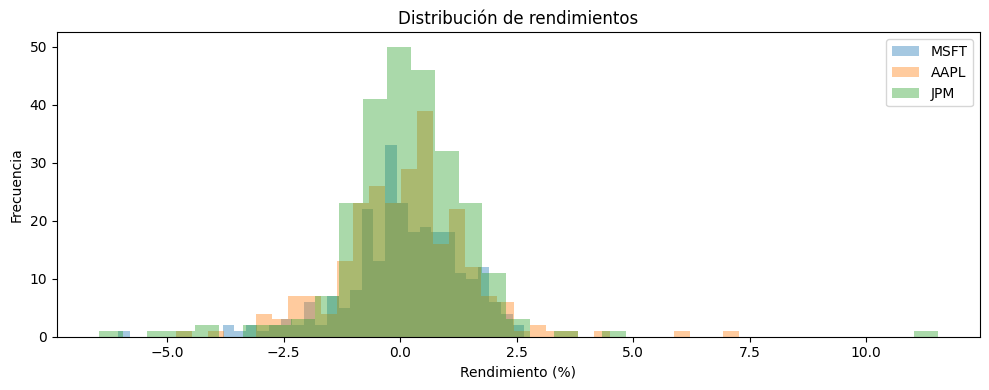

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
for ticker in rendimientos_pct.columns:
    ax.hist(rendimientos_pct[ticker], bins=35, alpha=0.4, label=ticker)
ax.set(title="Distribución de rendimientos", xlabel="Rendimiento (%)", ylabel="Frecuencia")
ax.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_584/1471857928.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([rendimientos_pct[t].to_numpy() for t in rendimientos_pct.columns],


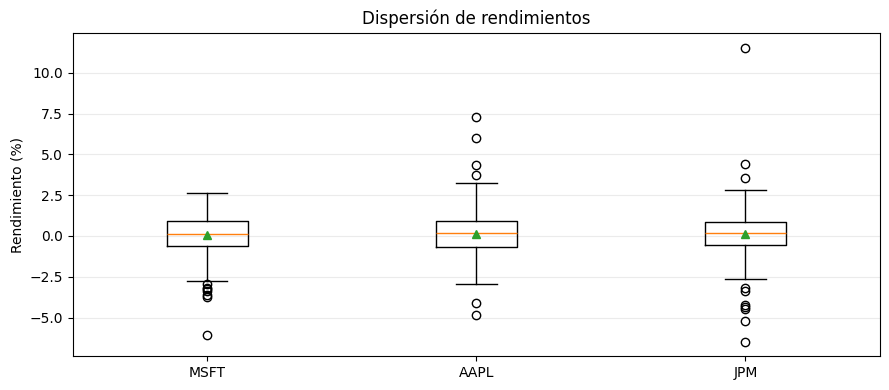

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([rendimientos_pct[t].to_numpy() for t in rendimientos_pct.columns],
           labels=list(rendimientos_pct.columns), showmeans=True)
ax.set(title="Dispersión de rendimientos", ylabel="Rendimiento (%)")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretación guiada:** los precios normalizados muestran variaciones relativas acumuladas del nivel de cotización. El histograma permite observar concentración y colas. El diagrama de caja facilita comparar medianas y dispersión central. La forma del histograma, por sí sola, no prueba que una distribución sea normal.

**Tu práctica 6:** redacta una interpretación para cada gráfico. Diferencia explícitamente lo observado de las conclusiones que no pueden sostenerse.

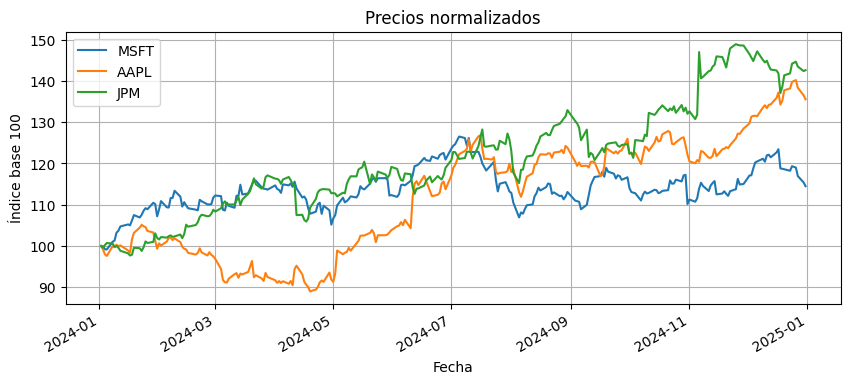

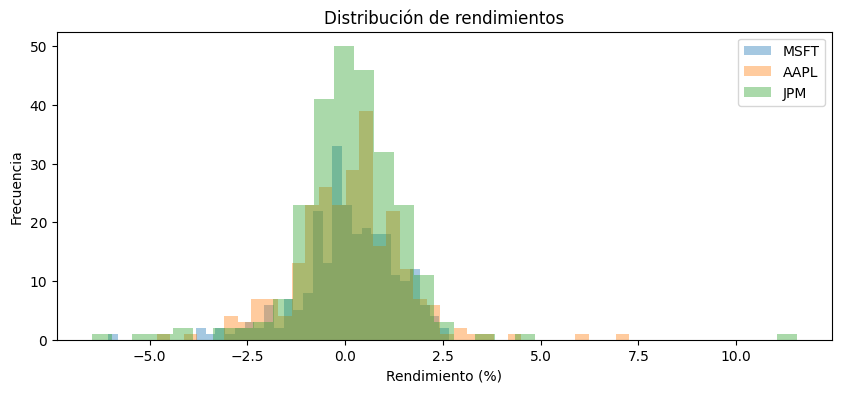

/tmp/ipykernel_584/140500330.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


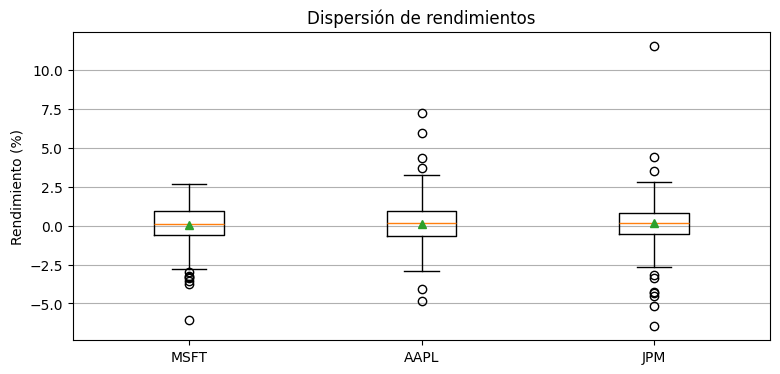

In [ ]:
# 1. Gráfico de precios normalizados
normalizados = precios.div(precios.iloc[0]).mul(100)

normalizados.plot(figsize=(10, 4), title="Precios normalizados")
plt.xlabel("Fecha")
plt.ylabel("Índice base 100")
plt.grid()
plt.show()


# 2. Histograma de rendimientos
plt.figure(figsize=(10, 4))

for ticker in rendimientos_pct.columns:
    plt.hist(rendimientos_pct[ticker], bins=35,
             alpha=0.4, label=ticker)

plt.title("Distribución de rendimientos")
plt.xlabel("Rendimiento (%)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()


# 3. Diagrama de caja (Boxplot)
plt.figure(figsize=(9, 4))

plt.boxplot(
    [rendimientos_pct[t].dropna() for t in rendimientos_pct.columns],
    labels=rendimientos_pct.columns,
    showmeans=True
)

plt.title("Dispersión de rendimientos")
plt.ylabel("Rendimiento (%)")
plt.grid(axis="y")
plt.show()

1. Gráfico de precios normalizados: permite comparar la evolución de los tres activos desde una misma base de 100. Se observa cuál tuvo mayor crecimiento o disminución, pero no permite asegurar su comportamiento futuro.

2. Histograma de rendimientos: muestra la frecuencia y distribución de las variaciones diarias. Permite identificar concentraciones y valores extremos, pero no predecir rendimientos futuros.

3. Diagrama de caja (Boxplot): permite comparar la dispersión, la mediana y los valores atípicos de cada activo. Una mayor dispersión indica más variabilidad, pero no significa necesariamente una peor inversión

## 7 · Integrar los indicadores en un informe

Una conclusión rigurosa conecta varios resultados. Un activo puede presentar una media histórica más alta y, al mismo tiempo, una dispersión mayor. No existe una clasificación automática de «mejor activo» sin conocer objetivos y restricciones de inversión.

Distingue siempre **descripción** (qué ocurrió), **interpretación** (qué significa) y **limitación** (qué no podemos concluir).

In [ ]:
resumen = pd.DataFrame({
    "Media (%)": rendimientos_pct.mean(),
    "Mediana (%)": rendimientos_pct.median(),
    "Desv. estándar (%)": rendimientos_pct.std(ddof=1),
    "Percentil 5 (%)": rendimientos_pct.quantile(0.05),
    "Percentil 95 (%)": rendimientos_pct.quantile(0.95),
    "Mínimo (%)": rendimientos_pct.min(),
    "Máximo (%)": rendimientos_pct.max(),
    "N": rendimientos_pct.count()
})
display(resumen.round(4))
resumen.to_csv("resumen_exploratorio_portafolio.csv", index_label="Ticker")
print("Archivo creado: resumen_exploratorio_portafolio.csv")

**Tu práctica 7:** redacta entre 100 y 150 palabras comparando los activos mediante media, mediana, dispersión y al menos un gráfico. Sustenta cada afirmación en una medida calculada.

In [ ]:
comparacion = pd.DataFrame({
    "Media (%)": rendimientos_pct.mean(),
    "Mediana (%)": rendimientos_pct.median(),
    "Desviación estándar (%)": rendimientos_pct.std()
})

display(comparacion.round(4))

,Media (%),Mediana (%),Desviación estándar (%)
MSFT,0.0619,0.1154,1.2567
AAPL,0.1312,0.1596,1.4123
JPM,0.1524,0.1710,1.4815


El análisis de MSFT, AAPL y JPM permite comparar su comportamiento durante el periodo estudiado. La media muestra el rendimiento promedio de cada activo, mientras que la mediana representa el valor central de sus variaciones. La desviación estándar permite identificar cuál presentó mayor dispersión y volatilidad. Al observar el histograma, se pueden comparar las distribuciones de los rendimientos e identificar posibles valores extremos. El activo con mayor desviación estándar presentó mayores fluctuaciones, mientras que el de menor desviación tuvo un comportamiento más estable. Estas medidas permiten evaluar las diferencias entre los activos, aunque no garantizan su rentabilidad futura ni determinan por sí solas cuál es la mejor inversión.

## 8 · Reto integrador: informe exploratorio de un portafolio

Desarrolla un análisis original con tres activos y un período explícito. Debe incluir:

1. Pregunta de análisis, selección de activos y fuente.
2. Diagnóstico de fechas, tipos, datos faltantes y alineación.
3. Rendimientos simples y comprobación manual de una observación.
4. Media, mediana, desviación estándar, mínimos, máximos y cuartiles.
5. Comprobación manual de la media y desviación estándar de cinco rendimientos.
6. Gráficos de precios normalizados, histograma y diagrama de caja.
7. Interpretación comparativa de **180 a 250 palabras**, con supuestos y limitaciones.
8. Exportación del resumen estadístico a CSV.

**Evidencia:** notebook ejecutable con código, cálculos, gráficos rotulados y conclusiones. Documenta el uso de recursos externos o herramientas de IA. No inventes resultados si falla la consulta.


Diagnóstico de MSFT
Primera fecha: 2024-01-02
Última fecha: 2024-12-31
Dimensiones: (252, 5)
Tipos de datos:
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object
Valores faltantes: 0
Fechas duplicadas: 0
Precios no positivos: 0

Diagnóstico de AAPL
Primera fecha: 2024-01-02
Última fecha: 2024-12-31
Dimensiones: (252, 5)
Tipos de datos:
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object
Valores faltantes: 0
Fechas duplicadas: 0
Precios no positivos: 0

Diagnóstico de JPM
Primera fecha: 2024-01-02
Última fecha: 2024-12-31
Dimensiones: (252, 5)
Tipos de datos:
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object
Valores faltantes: 0
Fechas duplicadas: 0
Precios no positivos: 0

Fechas comunes antes de limpiar: 252

Base final:
Primera fecha: 2024-01-02
Última fecha: 2024-12-31
Observaciones: 252
Cantidad de activos: 3


,MSFT,AAPL,JPM
Date,,,
2024-01-02,363.117920,183.403992,161.472733
2024-01-03,362.853546,182.030777,160.768951
2024-01-04,360.249176,179.718948,161.835831
2024-01-05,360.063141,178.997696,162.647827
2024-01-08,366.858093,183.324966,162.411758


,MSFT,AAPL,JPM
Date,,,
2024-01-03,-0.072807,-0.748738,-0.435851
2024-01-04,-0.717747,-1.270021,0.663610
2024-01-05,-0.051641,-0.401322,0.501741
2024-01-08,1.887156,2.417501,-0.145141
2024-01-09,0.293573,-0.226329,-0.790600



Comprobación manual del rendimiento:
Manual: -0.007487376413986446
Pandas: -0.007487376413986446

Resumen estadístico:


,Media (%),Mediana (%),Desviación estándar (%),Mínimo (%),Máximo (%),Q1 (%),Q2 (%),Q3 (%),IQR (%)
MSFT,0.0619,0.1154,1.2567,-6.0528,2.6599,-0.6056,0.1154,0.9165,1.5220
AAPL,0.1312,0.1596,1.4123,-4.8167,7.2649,-0.6713,0.1596,0.9332,1.6045
JPM,0.1524,0.1710,1.4815,-6.4678,11.5445,-0.5579,0.1710,0.8482,1.4061



Comprobación de los primeros cinco rendimientos de AAPL:
Media manual: -0.04578
Media pandas: -0.04578
Desviación manual: 1.4335
Desviación pandas: 1.4335


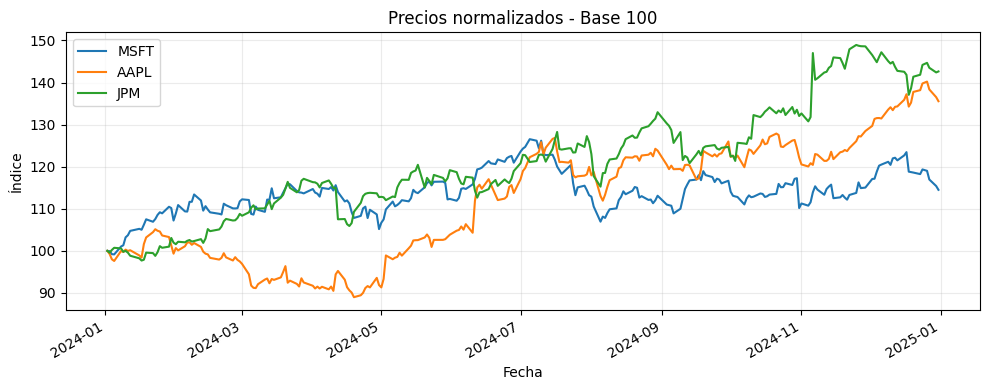

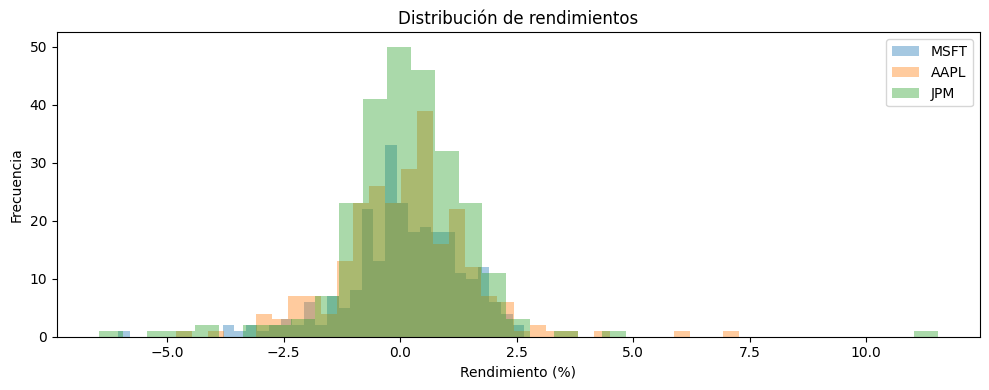

/tmp/ipykernel_584/2314790593.py:152: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


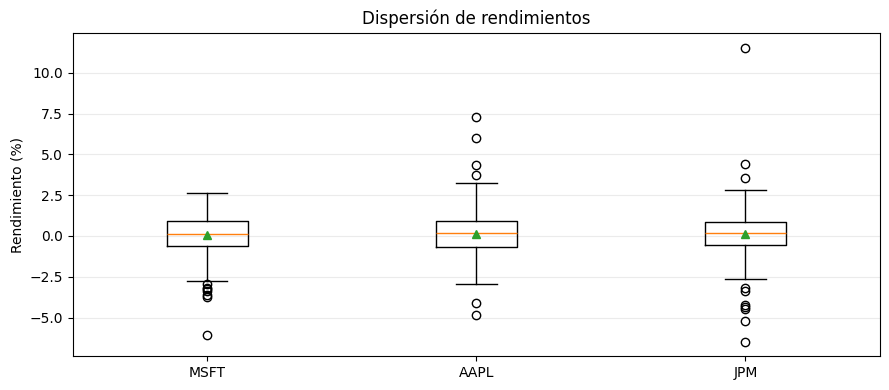


Archivo exportado: resumen_estadistico.csv


In [ ]:
# ==========================================
# RETO: ANÁLISIS FINANCIERO DE TRES ACTIVOS
# ==========================================

%pip -q install yfinance pandas numpy matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

# 1. Selección de activos y período
TICKERS = ["MSFT", "AAPL", "JPM"]
INICIO = "2024-01-01"
FIN = "2025-01-01"

# 2. Descarga y diagnóstico de datos
series = []

for ticker in TICKERS:
    tabla = yf.download(
        ticker,
        start=INICIO,
        end=FIN,
        auto_adjust=True,
        progress=False,
        multi_level_index=False
    )

    if tabla.empty or "Close" not in tabla.columns:
        raise RuntimeError(f"No se pudieron descargar datos de {ticker}")

    cierre = tabla["Close"]

    print(f"\nDiagnóstico de {ticker}")
    print("Primera fecha:", tabla.index.min().date())
    print("Última fecha:", tabla.index.max().date())
    print("Dimensiones:", tabla.shape)
    print("Tipos de datos:")
    print(tabla.dtypes)
    print("Valores faltantes:", cierre.isna().sum())
    print("Fechas duplicadas:", tabla.index.duplicated().sum())
    print("Precios no positivos:", (cierre <= 0).sum())

    series.append(cierre.rename(ticker))

# 3. Alineación y limpieza de precios
precios = pd.concat(series, axis=1, join="inner")
print("\nFechas comunes antes de limpiar:", len(precios))

precios.index = pd.to_datetime(precios.index)
precios = precios.sort_index()
precios = precios.loc[~precios.index.duplicated(keep="first")]
precios = precios.apply(pd.to_numeric, errors="coerce")
precios = precios.dropna(how="any")
precios = precios.loc[(precios > 0).all(axis=1)]

if len(precios) < 6:
    raise RuntimeError("No hay suficientes observaciones válidas.")

print("\nBase final:")
print("Primera fecha:", precios.index.min().date())
print("Última fecha:", precios.index.max().date())
print("Observaciones:", len(precios))
print("Cantidad de activos:", precios.shape[1])
display(precios.head())

# 4. Cálculo de rendimientos simples
rendimientos = precios.pct_change(fill_method=None).dropna(how="any")
rendimientos_pct = rendimientos * 100

display(rendimientos_pct.head())

# 5. Comprobación manual de un rendimiento
activo = "AAPL"

manual = precios[activo].iloc[1] / precios[activo].iloc[0] - 1
calculado = rendimientos[activo].iloc[0]

print("\nComprobación manual del rendimiento:")
print("Manual:", manual)
print("Pandas:", calculado)

assert np.isclose(manual, calculado)

# 6. Estadísticas descriptivas
resumen = pd.DataFrame({
    "Media (%)": rendimientos_pct.mean(),
    "Mediana (%)": rendimientos_pct.median(),
    "Desviación estándar (%)": rendimientos_pct.std(ddof=1),
    "Mínimo (%)": rendimientos_pct.min(),
    "Máximo (%)": rendimientos_pct.max(),
    "Q1 (%)": rendimientos_pct.quantile(0.25),
    "Q2 (%)": rendimientos_pct.quantile(0.50),
    "Q3 (%)": rendimientos_pct.quantile(0.75)
})

resumen["IQR (%)"] = resumen["Q3 (%)"] - resumen["Q1 (%)"]

print("\nResumen estadístico:")
display(resumen.round(4))

# 7. Comprobación manual de media y desviación estándar
muestra = rendimientos_pct["AAPL"].iloc[:5].to_numpy()

media_manual = sum(muestra) / len(muestra)
desviacion_manual = np.sqrt(
    ((muestra - media_manual) ** 2).sum() / (len(muestra) - 1)
)

assert np.isclose(media_manual, muestra.mean())
assert np.isclose(desviacion_manual, pd.Series(muestra).std(ddof=1))

print("\nComprobación de los primeros cinco rendimientos de AAPL:")
print("Media manual:", round(media_manual, 5))
print("Media pandas:", round(muestra.mean(), 5))
print("Desviación manual:", round(desviacion_manual, 5))
print("Desviación pandas:", round(pd.Series(muestra).std(ddof=1), 5))

# 8. Gráfico de precios normalizados
normalizados = precios.div(precios.iloc[0]).mul(100)

normalizados.plot(figsize=(10, 4))
plt.title("Precios normalizados - Base 100")
plt.xlabel("Fecha")
plt.ylabel("Índice")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 9. Histograma de rendimientos
plt.figure(figsize=(10, 4))

for ticker in rendimientos_pct.columns:
    plt.hist(
        rendimientos_pct[ticker],
        bins=35,
        alpha=0.4,
        label=ticker
    )

plt.title("Distribución de rendimientos")
plt.xlabel("Rendimiento (%)")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

# 10. Diagrama de caja
plt.figure(figsize=(9, 4))

plt.boxplot(
    [rendimientos_pct[t].to_numpy() for t in rendimientos_pct.columns],
    labels=list(rendimientos_pct.columns),
    showmeans=True
)

plt.title("Dispersión de rendimientos")
plt.ylabel("Rendimiento (%)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# 11. Exportación del resumen a CSV
resumen.round(4).to_csv("resumen_estadistico.csv", index=True)

print("\nArchivo exportado: resumen_estadistico.csv")

El análisis de Microsoft (MSFT), Apple (AAPL) y JPMorgan Chase (JPM), durante el periodo comprendido entre el 2 de enero y el 31 de diciembre de 2024, permitió comparar el comportamiento de sus rendimientos diarios.

Los tres activos registraron 252 observaciones, sin valores faltantes, fechas duplicadas ni precios no positivos. En cuanto a la media, JPM presentó el mayor rendimiento promedio (0,1524 %), seguido de AAPL (0,1312 %) y MSFT (0,0619 %). Las medianas también fueron positivas: JPM (0,1710 %), AAPL (0,1596 %) y MSFT (0,1154 %).

Respecto a la desviación estándar, JPM presentó la mayor variabilidad (1,4815 %), seguido de AAPL (1,4123 %) y MSFT (1,2567 %), indicando que Microsoft tuvo los rendimientos menos dispersos. Los valores máximos y mínimos muestran movimientos importantes, especialmente en JPM, cuyo máximo diario fue 11,5445 %.

Los gráficos de precios normalizados, histogramas y diagramas de caja complementan estas medidas al permitir observar la evolución, distribución y dispersión de los rendimientos. Se concluye que JPM tuvo el mayor rendimiento promedio, mientras que MSFT presentó menor variabilidad. Sin embargo, estos resultados son históricos y no garantizan rentabilidades futuras. El análisis tampoco contempla comisiones, impuestos ni otros costos de inversión.

## 9 · Autoevaluación y continuidad

- [ ] Distingo precios de rendimientos.
- [ ] Verifico manualmente un rendimiento simple.
- [ ] Interpreto media y mediana sin confundirlas con rendimiento acumulado.
- [ ] Comprendo la desviación estándar muestral y sus limitaciones.
- [ ] Examino cuantiles y observaciones extremas.
- [ ] Utilizo gráficos adecuados y explico sus resultados.
- [ ] Documento las decisiones metodológicas y la fuente.

**Próximo módulo:** series temporales financieras: frecuencia, tendencia, medias móviles, volatilidad móvil y rendimientos acumulados.

**Referencias:** [pandas](https://pandas.pydata.org/docs/) · [NumPy](https://numpy.org/doc/stable/) · [matplotlib](https://matplotlib.org/stable/) · [yfinance](https://ranaroussi.github.io/yfinance/).

Los resultados históricos son descriptivos y no constituyen recomendaciones de inversión.

## Quiz de cierre · Análisis exploratorio

**Quiz evaluativo 3 de 4 · componente de quices (15 % total)**

Responde individualmente las cinco preguntas. Las respuestas deben ser originales, razonadas y coherentes con el código que ejecutes. No basta con escribir una definición: explica el significado de los resultados cuando se solicite.

**Criterio sugerido:** cada pregunta vale 1 punto (5 puntos en total). Las preguntas 1–2 evalúan comprensión, 3–4 interpretación y 5 aplicación. La docente verificará las respuestas y registrará la nota conforme a la ponderación institucional de cada quiz.

### Pregunta 1 · Comprensión

¿Por qué no es correcto comparar directamente precios nominales para determinar cuál activo fue más rentable?

**Tu respuesta:**

No es correcto comparar precios nominales porque cada activo tiene un precio diferente. Para determinar cuál fue más rentable debemos comparar sus rendimientos porcentuales y no el valor de sus acciones.

### Pregunta 2 · Comprensión

Explica qué informa la desviación estándar de los rendimientos.

**Tu respuesta:**

La desviación estándar indica qué tanto varían los rendimientos respecto a su promedio. Una desviación alta representa mayor volatilidad y una baja indica mayor estabilidad.

### Pregunta 3 · Interpretación

Un activo tiene rendimiento medio diario positivo y volatilidad alta. ¿Qué podemos concluir y qué no?

**Tu respuesta:**

Podemos concluir que el activo tuvo un rendimiento promedio positivo, pero presentó variaciones importantes. No podemos asegurar que siempre genere ganancias ni que sea una buena inversión.

### Pregunta 4 · Interpretación

¿Cómo interpretarías una correlación de -0.7 entre rendimientos de dos activos?

**Tu respuesta:**

Una correlación de -0.7 indica una relación negativa considerable entre los rendimientos de dos activos. Generalmente, cuando uno sube, el otro tiende a bajar, lo que puede ayudar a diversificar una inversión.

### Pregunta 5 · Aplicación

Crea una serie de al menos cinco rendimientos diarios, calcula media y desviación estándar con pandas y escribe una interpretación.

**Tu respuesta:**

_Escribe aquí tu explicación. Si se solicita código, utiliza la celda de Python siguiente._



In [ ]:
import pandas as pd

rendimientos = pd.Series([1.2, -0.5, 0.8, 1.5, -0.3])

media = rendimientos.mean()
desviacion = rendimientos.std()

print("Media:", media)
print("Desviación estándar:", desviacion)


Media: 0.54
Desviación estándar: 0.8961026726887941


La media representa el rendimiento promedio de los cinco días. La desviación estándar muestra qué tanto variaron los rendimientos. En este ejemplo, el promedio es positivo, lo que indica un comportamiento favorable durante el periodo analizado.